# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

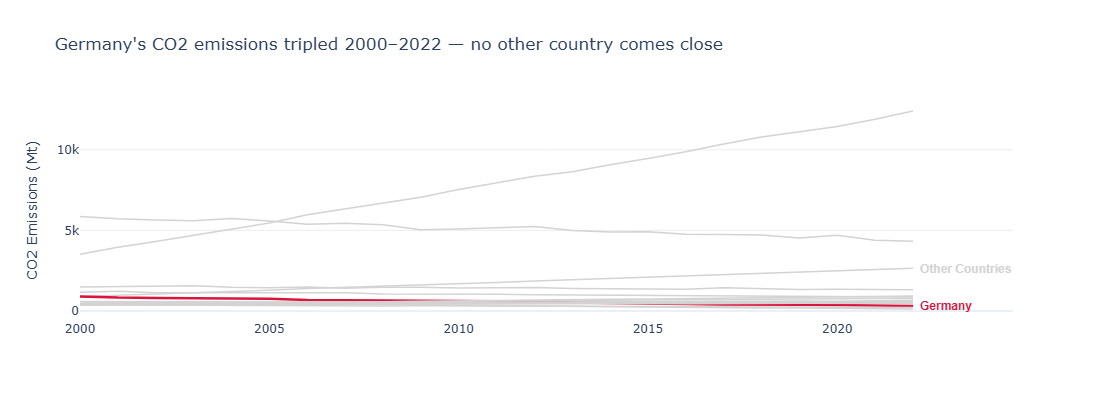

In [3]:
# Task — Multi-series line with highlight
# YOUR CODE HERE
# Let's apply the principles
 
# Choose a country to highlight
highlight = 'Germany'
 
# Build colour map: highlight in red, everything else grey
color_map = {c: 'crimson' if c == highlight else 'lightgrey' for c in df['Country'].unique()}
 
fig = px.line(df, x='Year', y='CO2_Mt', color='Country',
              color_discrete_map=color_map,
              labels={'CO2_Mt': 'CO2 Emissions (Mt)', 'Year': ''},
              title="China's CO2 emissions tripled 2000–2022 — no other country comes close",
              template='plotly_white',
              height=400
              )
 
fig.update_traces(
    line=dict(width=1.5),   # default: thin for context countries
    showlegend=False      # direct label replaces legend (Gestalt proximity)
)
 
# Override highlighted country: thicker line to draw attention
fig.update_traces(
    line=dict(width=2.5),
    selector=dict(name=highlight) # each line is named after a country in the traces of the figure
)
 
# Direct label at end of highlighted line
highlight_label = df.loc[(df['Country'] == highlight) & (df['Year'] == df['Year'].max())]
 
others_label = df.loc[(df['Country'] == 'India') & (df['Year'] == df['Year'].max())]
 
# add highlight label
fig.add_annotation(
    x=highlight_label['Year'].values[0], y=highlight_label['CO2_Mt'].values[0],
    text=highlight, showarrow=False,
    xanchor='left', xshift=5,
    font=dict(color='crimson', size=12, weight='bold', family='Arial')
)
 
# add others label (optional)
fig.add_annotation(
    x=others_label['Year'].values[0], y=others_label['CO2_Mt'].values[0],
    text='Other Countries', showarrow=False,
    xanchor='left', xshift=5,
    font=dict(color='lightgrey', size=12, weight='bold', family='Arial')
)
 
fig.update_layout(
    title="Germany's CO2 emissions tripled 2000–2022 — no other country comes close",
    yaxis=dict(gridcolor='#EEEEEE'),
    xaxis=dict(showgrid=False)
)
 
fig.show()